# A simulated data stream of a next-generation detector

Next-generation detectors such as the Einstein Telescope will record many signals at the same time.
This notebook draws one minute of simulated data: Gaussian noise plus a few compact-binary signals.

The purpose is only to illustrate the idea of long and overlapping signals.
The signals are simple leading-order ("Newtonian") chirps, and their amplitudes are chosen by hand
so that they are visible in the plot. This is not a realistic simulation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from gwr_style import COLORS, TEXTWIDTH, save_figure

rng = np.random.default_rng(4)  # random number generator with a fixed seed

## A simple chirp

At leading order, a binary that merges at time $t_c$ has a gravitational-wave frequency

$$f(t) = \frac{1}{\pi}\left(\frac{5}{256\,(t_c - t)}\right)^{3/8}\left(\frac{G\mathcal{M}_d}{c^3}\right)^{-5/8}.$$

The amplitude grows as $f^{2/3}$, and the phase is $2\pi$ times the integral of the frequency.
We stop the signal at a maximum frequency, as a crude stand-in for the merger.

In [2]:
G_MSUN_C3 = 4.925491e-6  # G * (one solar mass) / c^3, in seconds


def chirp(t, t_merger, chirp_mass, amplitude, f_min=5.0, f_max=120.0):
    """Toy inspiral signal as a function of time.

    t           : array of times in seconds
    t_merger    : time of the merger in seconds
    chirp_mass  : chirp mass in solar masses
    amplitude   : amplitude of the signal when it reaches f_max (arbitrary units)
    f_min, f_max: the signal is shown only between these two frequencies (Hz)
    """
    signal = np.zeros_like(t)
    before_merger = t < t_merger
    tau = t_merger - t[before_merger]  # time left before merger

    # Frequency as a function of time (formula above)
    frequency = (5.0 / 256.0 / tau) ** (3.0 / 8.0) / (np.pi * (G_MSUN_C3 * chirp_mass) ** (5.0 / 8.0))

    # Phase: 2 pi times the integral of the frequency, which can be done analytically
    phase = -2.0 * (tau / (5.0 * G_MSUN_C3 * chirp_mass)) ** (5.0 / 8.0)

    # Amplitude grows as frequency^(2/3); keep only the part inside the band
    in_band = (frequency > f_min) & (frequency < f_max)
    values = amplitude * (frequency / f_max) ** (2.0 / 3.0) * np.cos(phase)
    signal[before_merger] = np.where(in_band, values, 0.0)
    return signal

## Noise and signals

We simulate 60 seconds of data, sampled 512 times per second.
The noise is white and Gaussian with unit standard deviation.
We then add seven signals of three kinds: binary neutron stars, neutron star-black hole binaries
and binary black holes.

In [3]:
duration = 60.0        # seconds
sampling_rate = 512.0  # samples per second
t = np.arange(0, duration, 1.0 / sampling_rate)

noise = rng.standard_normal(t.size)

# Each signal: (kind, merger time [s], chirp mass [solar masses], amplitude)
signals = [
    ("Binary neutron stars", 44.0, 1.2, 3.0),
    ("Binary neutron stars", 75.0, 1.3, 2.4),   # merges after the end of the plot
    ("Binary neutron stars", 140.0, 1.1, 2.0),  # merges well after the end of the plot
    ("Neutron star-black hole", 29.0, 3.0, 3.6),
    ("Neutron star-black hole", 66.0, 2.6, 3.0),
    ("Binary black holes", 16.0, 28.0, 5.5),
    ("Binary black holes", 52.0, 45.0, 6.5),
]
color_of = {
    "Binary neutron stars": COLORS["blue"],
    "Neutron star-black hole": COLORS["teal"],
    "Binary black holes": COLORS["orange"],
}

waveforms = [chirp(t, t_merger, mc, amp) for _, t_merger, mc, amp in signals]

# The data are the sum of the noise and of all the signals
data = noise + np.sum(waveforms, axis=0)

## The figure

The grey line is the data. The coloured lines are the signals hidden in it.
Binary neutron stars are in band for the whole minute. Binary black holes last only a few seconds.

Figure saved to output/fig_data_stream.pdf


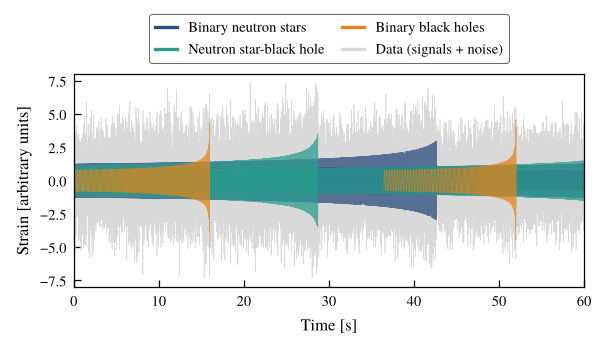

In [4]:
fig, ax = plt.subplots(figsize=(TEXTWIDTH, 0.42 * TEXTWIDTH))

ax.plot(t, data, color=COLORS["lightgrey"], lw=0.3, rasterized=True)
for (kind, _, _, _), waveform in zip(signals, waveforms):
    visible = waveform != 0.0
    ax.plot(t[visible], waveform[visible], color=color_of[kind], lw=0.25, alpha=0.75, rasterized=True)

# One legend entry per kind of source
for kind, color in color_of.items():
    ax.plot([], [], color=color, lw=1.6, label=kind)
ax.plot([], [], color=COLORS["lightgrey"], lw=1.6, label="Data (signals + noise)")

ax.set_xlim(0, duration)
ax.set_ylim(-8, 8)
ax.set_xlabel("Time [s]")
ax.set_ylabel("Strain [arbitrary units]")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, handlelength=1.5, columnspacing=1.2)

save_figure(fig, "fig_data_stream.pdf")
plt.show()